In [1]:
# PyTorch library import karta hai (deep learning models banane ke liye)
import torch

# Neural network modules import karta hai
import torch.nn as nn

# Optimization algorithms import karta hai (model training ke liye)
import torch.optim as optim

# Custom dataset aur data batches banane ke liye import karta hai
from torch.utils.data import Dataset, DataLoader

# Image preprocessing aur pre-trained models import karta hai
from torchvision import transforms, models

# Images open aur process karne ke liye PIL import karta hai
from PIL import Image

# CSV aur tabular data handle karne ke liye Pandas import karta hai
import pandas as pd

# Arrays aur numerical operations ke liye NumPy import karta hai
import numpy as np

# File aur folder operations ke liye os module import karta hai
import os

# Images aur graphs display karne ke liye Matplotlib import karta hai
import matplotlib.pyplot as plt

# Model evaluation metrics import karta hai
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Installed PyTorch version print karta hai
print("PyTorch version:", torch.__version__)

# Confirm karta hai ki sabhi libraries successfully load ho gayi hain
print("All libraries loaded!")

PyTorch version: 2.12.1+cpu
All libraries loaded!


In [2]:
# Labels ko numeric values me convert karne ke liye mapping banata hai
label_map = {'good': 0, 'average': 1, 'poor': 2}

# Custom Dataset class define karta hai
class WebsiteDataset(Dataset):

    # Dataset initialize karta hai
    def __init__(self, dataframe, images_dir, transform=None):
        self.df = dataframe
        self.images_dir = images_dir
        self.transform = transform

    # Dataset me total samples ki sankhya return karta hai
    def __len__(self):
        return len(self.df)

    # Given index ke liye image aur label return karta hai
    def __getitem__(self, idx):

        # Current image ka filename leta hai
        img_name = self.df.iloc[idx]['filename']

        # Image ka complete path banata hai
        img_path = os.path.join(self.images_dir, img_name)

        # Image ko open karke RGB format me convert karta hai
        image = Image.open(img_path).convert('RGB')

        # Agar transform diya gaya ho to image par apply karta hai
        if self.transform:
            image = self.transform(image)

        # Label ko text se numeric value me convert karta hai
        label = label_map[self.df.iloc[idx]['label']]

        # Image aur label return karta hai
        return image, label

# Confirm karta hai ki Dataset class successfully define ho gayi hai
print("Dataset class defined!")

Dataset class defined!


In [3]:
# Paths
# Images folder ka path define karta hai
IMAGES_DIR = r"C:\Projects\Internship_Learning\dataset\images"

# Labels CSV file ka path define karta hai
LABELS_PATH = r"C:\Projects\Internship_Learning\dataset\labels.csv"

# Load labels
# Labels CSV ko DataFrame me load karta hai
df_labels = pd.read_csv(LABELS_PATH)

# Train/test split
from sklearn.model_selection import train_test_split

# Dataset ko train aur test set me split karta hai
train_df, test_df = train_test_split(
    df_labels, test_size=0.2, random_state=42, stratify=df_labels['label']
)
print("Train size:", len(train_df))
print("Test size:", len(test_df))

# Transforms - ImageNet normalization
# Image preprocessing pipeline define karta hai
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Datasets and DataLoaders
# Training aur testing dataset banata hai
train_dataset = WebsiteDataset(train_df.reset_index(drop=True), IMAGES_DIR, transform)
test_dataset = WebsiteDataset(test_df.reset_index(drop=True), IMAGES_DIR, transform)

# Training aur testing DataLoader banata hai
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)
print("DataLoaders ready!")

Train size: 160
Test size: 40
DataLoaders ready!


In [4]:
# Pre-trained ResNet18 model load karta hai
# weights='IMAGENET1K_V1' -> ImageNet dataset par pehle se trained weights use karta hai
model = models.resnet18(weights='IMAGENET1K_V1')

# Model ki sabhi layers ko freeze karta hai
for param in model.parameters():
    param.requires_grad = False

# Final Fully Connected (FC) layer ko replace karta hai
# 512 input features aur 3 output classes (good, average, poor)
model.fc = nn.Linear(512, 3)

# Modified ResNet18 successfully load hone ka message print karta hai
print("ResNet18 loaded and modified!")

# Final output layer print karta hai
print("\nFinal layer:", model.fc)

# Sirf train hone wale parameters ki total count print karta hai
print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# Freeze kiye gaye parameters ki total count print karta hai
print("Frozen parameters:",
      sum(p.numel() for p in model.parameters() if not p.requires_grad))

ResNet18 loaded and modified!

Final layer: Linear(in_features=512, out_features=3, bias=True)

Trainable parameters: 1539
Frozen parameters: 11176512


In [5]:
# Multi-class classification ke liye loss function define karta hai
criterion = nn.CrossEntropyLoss()

# Adam optimizer define karta hai
# Sirf final FC layer ke parameters train honge
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Total training epochs define karta hai
EPOCHS = 15

# Har epoch ka training loss store karne ke liye list banata hai
train_losses = []

# Har epoch ki training accuracy store karne ke liye list banata hai
train_accuracies = []

# Har epoch ki validation accuracy store karne ke liye list banata hai
val_accuracies = []

# Best validation accuracy store karne ke liye variable
best_val_acc = 0.0

# Best model save karne ka path define karta hai
MODEL_SAVE_PATH = r"C:\Projects\Internship_Learning\model\best_model.pth"

# Training start hone ka message print karta hai
print("Training started...")
print("="*55)

# Model ko specified epochs tak train karta hai
for epoch in range(EPOCHS):
    
    # Model ko training mode me set karta hai
    model.train()
    
    # Running loss initialize karta hai
    running_loss = 0.0
    
    # Correct predictions count initialize karta hai
    correct = 0
    
    # Total samples count initialize karta hai
    total = 0
    
    # Training data ko batch-wise process karta hai
    for images, labels in train_loader:
        
        # Forward pass se predictions nikalta hai
        outputs = model(images)
        
        # Loss calculate karta hai
        loss = criterion(outputs, labels)
        
        # Previous gradients clear karta hai
        optimizer.zero_grad()
        
        # Backpropagation se gradients calculate karta hai
        loss.backward()
        
        # Final layer ke weights update karta hai
        optimizer.step()
        
        # Current batch ka loss add karta hai
        running_loss += loss.item()
        
        # Highest score wali class ko prediction maanta hai
        _, predicted = torch.max(outputs, 1)
        
        # Total samples count update karta hai
        total += labels.size(0)
        
        # Correct predictions count update karta hai
        correct += (predicted == labels).sum().item()
    
    # Current epoch ka average training loss calculate karta hai
    train_loss = round(running_loss / len(train_loader), 4)
    
    # Current epoch ki training accuracy calculate karta hai
    train_acc = round(correct / total * 100, 2)
    
    # Model ko evaluation mode me set karta hai
    model.eval()
    
    # Validation correct predictions initialize karta hai
    val_correct = 0
    
    # Validation total samples initialize karta hai
    val_total = 0
    
    # Validation ke dauran gradients disable karta hai
    with torch.no_grad():
        
        # Validation data ko batch-wise process karta hai
        for images, labels in test_loader:
            
            # Predictions nikalta hai
            outputs = model(images)
            
            # Highest score wali class ko prediction maanta hai
            _, predicted = torch.max(outputs, 1)
            
            # Total validation samples update karta hai
            val_total += labels.size(0)
            
            # Correct validation predictions update karta hai
            val_correct += (predicted == labels).sum().item()
    
    # Validation accuracy calculate karta hai
    val_acc = round(val_correct / val_total * 100, 2)
    
    # Current epoch ka loss store karta hai
    train_losses.append(train_loss)
    
    # Current epoch ki training accuracy store karta hai
    train_accuracies.append(train_acc)
    
    # Current epoch ki validation accuracy store karta hai
    val_accuracies.append(val_acc)
    
    # Agar current validation accuracy best hai to model save karta hai
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        # Model ke learned weights save karta hai
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        # Model save hone ka message print karta hai
        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {train_loss} | Train: {train_acc}% | Val: {val_acc}% SAVED")
    else:
        # Model save nahi hua (best se better nahi tha) uska message print karta hai
        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {train_loss} | Train: {train_acc}% | Val: {val_acc}%")

# Training complete hone ka message print karta hai
print("="*55)

# Best validation accuracy print karta hai
print(f"Best Validation Accuracy: {best_val_acc}%")

Training started...
Epoch [1/15] Loss: 1.126 | Train: 40.0% | Val: 42.5% SAVED
Epoch [2/15] Loss: 1.026 | Train: 48.12% | Val: 42.5%
Epoch [3/15] Loss: 0.8825 | Train: 61.25% | Val: 60.0% SAVED
Epoch [4/15] Loss: 0.8383 | Train: 61.88% | Val: 55.0%
Epoch [5/15] Loss: 0.8318 | Train: 60.62% | Val: 62.5% SAVED
Epoch [6/15] Loss: 0.7685 | Train: 67.5% | Val: 55.0%
Epoch [7/15] Loss: 0.7082 | Train: 68.75% | Val: 67.5% SAVED
Epoch [8/15] Loss: 0.7194 | Train: 68.75% | Val: 65.0%
Epoch [9/15] Loss: 0.7009 | Train: 72.5% | Val: 55.0%
Epoch [10/15] Loss: 0.6826 | Train: 72.5% | Val: 65.0%
Epoch [11/15] Loss: 0.5917 | Train: 78.75% | Val: 65.0%
Epoch [12/15] Loss: 0.6295 | Train: 73.75% | Val: 62.5%
Epoch [13/15] Loss: 0.619 | Train: 77.5% | Val: 60.0%
Epoch [14/15] Loss: 0.5865 | Train: 78.75% | Val: 60.0%
Epoch [15/15] Loss: 0.6201 | Train: 77.5% | Val: 52.5%
Best Validation Accuracy: 67.5%


In [6]:
# Saved best model ke weights load karta hai
model.load_state_dict(torch.load(MODEL_SAVE_PATH))

# Model ko evaluation mode me set karta hai
model.eval()

# Sabhi predicted labels store karne ke liye list banata hai
all_preds = []

# Sabhi actual labels store karne ke liye list banata hai
all_labels = []

# Evaluation ke dauran gradient calculation disable karta hai
# Isse memory kam use hoti hai aur evaluation fast hota hai
with torch.no_grad():

    # Test data ko batch-wise process karta hai
    for images, labels in test_loader:

        # Model se predictions nikalta hai
        outputs = model(images)

        # Highest score wali class ko prediction maanta hai
        _, predicted = torch.max(outputs, 1)

        # Predicted labels list me add karta hai
        all_preds.extend(predicted.numpy())

        # Actual labels list me add karta hai
        all_labels.extend(labels.numpy())

# Numeric labels ke corresponding class names define karta hai
label_names = ['good', 'average', 'poor']

# Final test accuracy calculate aur print karta hai
print("Final Test Accuracy:", round(sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels) * 100, 2), "%")

# Classification Report ki heading print karta hai
print("\nClassification Report:")

# Precision, Recall aur F1-score report print karta hai
print(classification_report(all_labels, all_preds, target_names=label_names))

# Confusion Matrix ki heading print karta hai
print("\nConfusion Matrix:")

# Confusion Matrix print karta hai
print(confusion_matrix(all_labels, all_preds))

# Macro F1-score calculate karta hai
macro_f1 = round(f1_score(all_labels, all_preds, average='macro') * 100, 2)

# Macro F1-score print karta hai
print("\nMacro F1 Score:", macro_f1, "%")

Final Test Accuracy: 67.5 %

Classification Report:
              precision    recall  f1-score   support

        good       0.78      0.58      0.67        12
     average       0.69      0.69      0.69        16
        poor       0.60      0.75      0.67        12

    accuracy                           0.68        40
   macro avg       0.69      0.67      0.67        40
weighted avg       0.69      0.68      0.68        40


Confusion Matrix:
[[ 7  2  3]
 [ 2 11  3]
 [ 0  3  9]]

Macro F1 Score: 67.36 %


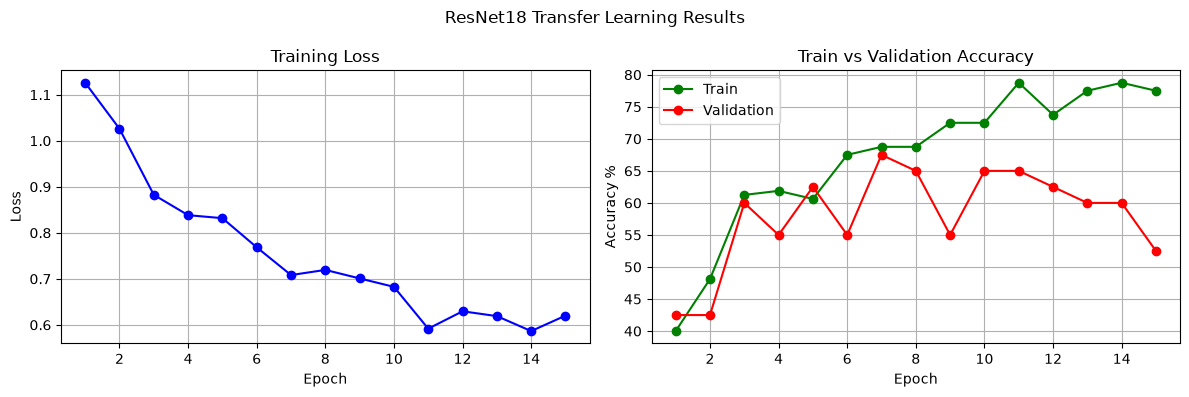

In [7]:
# Training curves plot karne ke liye figure create karta hai
plt.figure(figsize=(12, 4))

# Pehla subplot create karta hai
plt.subplot(1, 2, 1)

# Har epoch ka training loss plot karta hai
plt.plot(range(1, EPOCHS+1), train_losses, 'b-o')

# Graph ka title set karta hai
plt.title('Training Loss')

# X-axis ka label set karta hai
plt.xlabel('Epoch')

# Y-axis ka label set karta hai
plt.ylabel('Loss')

# Grid display karta hai
plt.grid(True)

# Dusra subplot create karta hai
plt.subplot(1, 2, 2)

# Har epoch ki training accuracy plot karta hai
plt.plot(range(1, EPOCHS+1), train_accuracies, 'g-o', label='Train')

# Har epoch ki validation accuracy plot karta hai
plt.plot(range(1, EPOCHS+1), val_accuracies, 'r-o', label='Validation')

# Graph ka title set karta hai
plt.title('Train vs Validation Accuracy')

# X-axis ka label set karta hai
plt.xlabel('Epoch')

# Y-axis ka label set karta hai
plt.ylabel('Accuracy %')

# Graph ke liye legend display karta hai
plt.legend()

# Grid display karta hai
plt.grid(True)

# Puri figure ka main title set karta hai
plt.suptitle('ResNet18 Transfer Learning Results', fontsize=12)

# Layout automatically adjust karta hai
plt.tight_layout()

# Graph display karta hai
plt.show()